# Missingness Indicators and Feature Retention Experiments

## Project
Machine Learning-Based Air Quality Classification System

## Objective
Investigate whether explicitly representing missing pollutant measurements improves AQI classification and whether retaining additional pollutant features improves model performance.

## Experiments
1. Median imputation vs. median imputation with missingness indicators.
2. Retaining 10, 11, and 12 pollutant features.

## Evaluation
- Accuracy
- Macro F1
- Weighted F1
- Class-wise precision and recall

A chronological validation strategy will be used for model selection.

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42

In [2]:
data_path = Path("../data/raw/city_hour.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (707875, 16)

Columns:
['City', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


,City,Datetime,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01 01:00:00,NaN,NaN,1.00,40.01,36.37,NaN,1.00,122.07,NaN,0.0,0.0,0.0,NaN,NaN
1,Ahmedabad,2015-01-01 02:00:00,NaN,NaN,0.02,27.75,19.73,NaN,0.02,85.90,NaN,0.0,0.0,0.0,NaN,NaN
2,Ahmedabad,2015-01-01 03:00:00,NaN,NaN,0.08,19.32,11.08,NaN,0.08,52.83,NaN,0.0,0.0,0.0,NaN,NaN
3,Ahmedabad,2015-01-01 04:00:00,NaN,NaN,0.30,16.45,9.20,NaN,0.30,39.53,153.58,0.0,0.0,0.0,NaN,NaN
4,Ahmedabad,2015-01-01 05:00:00,NaN,NaN,0.12,14.90,7.85,NaN,0.12,32.63,NaN,0.0,0.0,0.0,NaN,NaN


In [3]:
# Define the target and pollutant features

target = "AQI_Bucket"

features_10 = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene"
]

features_11 = features_10 + ["Toluene"]

features_12 = features_11 + ["Xylene"]

# Keep only observations with known target labels
model_df = df.loc[df[target].notna()].copy()

print("Labelled observations:", len(model_df))
print("10-feature configuration:", len(features_10))
print("11-feature configuration:", len(features_11))
print("12-feature configuration:", len(features_12))

Labelled observations: 578795
10-feature configuration: 10
11-feature configuration: 11
12-feature configuration: 12


In [4]:
# Convert Datetime to datetime format
model_df["Datetime"] = pd.to_datetime(model_df["Datetime"])

# Get unique timestamps in chronological order
timestamps = np.sort(model_df["Datetime"].unique())

# First split: 80% development period, 20% later test period
test_cutoff = timestamps[int(len(timestamps) * 0.80)]

development_df = model_df[
    model_df["Datetime"] < test_cutoff
].copy()

test_df = model_df[
    model_df["Datetime"] >= test_cutoff
].copy()

# Second split: 80% fitting period, 20% validation period
development_timestamps = np.sort(
    development_df["Datetime"].unique()
)

validation_cutoff = development_timestamps[
    int(len(development_timestamps) * 0.80)
]

train_df = development_df[
    development_df["Datetime"] < validation_cutoff
].copy()

validation_df = development_df[
    development_df["Datetime"] >= validation_cutoff
].copy()

print("TRAINING SET")
print("Shape:", train_df.shape)
print("Period:", train_df["Datetime"].min(), "to", train_df["Datetime"].max())

print("\nVALIDATION SET")
print("Shape:", validation_df.shape)
print("Period:", validation_df["Datetime"].min(), "to", validation_df["Datetime"].max())

print("\nTEST SET")
print("Shape:", test_df.shape)
print("Period:", test_df["Datetime"].min(), "to", test_df["Datetime"].max())

TRAINING SET
Shape: (242225, 16)
Period: 2015-01-01 16:00:00 to 2018-07-09 07:00:00

VALIDATION SET
Shape: (130370, 16)
Period: 2018-07-09 08:00:00 to 2019-05-26 12:00:00

TEST SET
Shape: (206200, 16)
Period: 2019-05-26 13:00:00 to 2020-07-01 00:00:00


In [5]:
# Separate features and target

X_train = train_df[features_10].copy()
y_train = train_df[target].copy()

X_val = validation_df[features_10].copy()
y_val = validation_df[target].copy()

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("\nValidation features:", X_val.shape)
print("Validation target:", y_val.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val.value_counts().sort_index())

Training features: (242225, 10)
Training target: (242225,)

Validation features: (130370, 10)
Validation target: (130370,)

Training class distribution:
AQI_Bucket
Good            10434
Moderate        83876
Poor            34947
Satisfactory    63431
Severe          15371
Very Poor       34166
Name: count, dtype: int64

Validation class distribution:
AQI_Bucket
Good             4378
Moderate        49578
Poor            16502
Satisfactory    38766
Severe           7820
Very Poor       13326
Name: count, dtype: int64


In [6]:
# Fit median imputer on training data
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)

print("Training shape:", X_train_imputed.shape)
print("Validation shape:", X_val_imputed.shape)

Training shape: (242225, 10)
Validation shape: (130370, 10)


In [7]:
baseline_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

baseline_model.fit(X_train_imputed, y_train)

y_val_pred_baseline = baseline_model.predict(X_val_imputed)

In [8]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_baseline))
print("Macro F1:", f1_score(y_val, y_val_pred_baseline, average="macro"))
print("Weighted F1:", f1_score(y_val, y_val_pred_baseline, average="weighted"))

Accuracy: 0.5930275370100483
Macro F1: 0.443902273181306
Weighted F1: 0.5695217387938798


In [9]:
# Create missingness indicators from original data
X_train_missing = X_train.isna().astype(int)
X_val_missing = X_val.isna().astype(int)

# Rename indicator columns
X_train_missing.columns = [
    col + "_missing" for col in X_train_missing.columns
]

X_val_missing.columns = [
    col + "_missing" for col in X_val_missing.columns
]

print("Training indicators:", X_train_missing.shape)
print("Validation indicators:", X_val_missing.shape)

print("\nTraining missingness counts:")
print(X_train_missing.sum().sort_values(ascending=False))

Training indicators: (242225, 10)
Validation indicators: (130370, 10)

Training missingness counts:
PM10_missing       118855
NH3_missing         99656
Benzene_missing     46894
NOx_missing         32502
CO_missing          17992
O3_missing          15986
SO2_missing         13916
PM2.5_missing       12098
NO_missing           9515
NO2_missing          8855
dtype: int64


In [10]:
# Convert imputed arrays back into DataFrames
X_train_imputed_df = pd.DataFrame(
    X_train_imputed,
    columns=features_10,
    index=X_train.index
)

X_val_imputed_df = pd.DataFrame(
    X_val_imputed,
    columns=features_10,
    index=X_val.index
)

# Combine pollutant values and missingness indicators
X_train_combined = pd.concat(
    [X_train_imputed_df, X_train_missing], axis=1
)

X_val_combined = pd.concat(
    [X_val_imputed_df, X_val_missing], axis=1
)

print("Combined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)

Combined training shape: (242225, 20)
Combined validation shape: (130370, 20)


In [11]:
indicator_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

indicator_model.fit(X_train_combined, y_train)

y_val_pred_indicator = indicator_model.predict(X_val_combined)

In [12]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_indicator))
print("Macro F1:", f1_score(y_val, y_val_pred_indicator, average="macro"))
print("Weighted F1:", f1_score(y_val, y_val_pred_indicator, average="weighted"))

Accuracy: 0.5930275370100483
Macro F1: 0.443902273181306
Weighted F1: 0.5695217387938798


In [13]:
# Compare predictions
print(
    "Identical predictions:",
    np.array_equal(y_val_pred_baseline, y_val_pred_indicator)
)

# Inspect feature importances
importance = pd.Series(
    indicator_model.feature_importances_,
    index=X_train_combined.columns
).sort_values(ascending=False)

print("\nFeature importances:")
print(importance)

Identical predictions: True

Feature importances:
PM2.5              0.743697
CO                 0.178671
O3                 0.034552
PM10               0.022802
NH3                0.012449
NOx                0.005933
NO                 0.001688
NO2                0.000164
NH3_missing        0.000045
SO2                0.000000
PM2.5_missing      0.000000
Benzene            0.000000
PM10_missing       0.000000
NO_missing         0.000000
NO2_missing        0.000000
NOx_missing        0.000000
CO_missing         0.000000
SO2_missing        0.000000
O3_missing         0.000000
Benzene_missing    0.000000
dtype: float64


In [14]:
np.array_equal(y_val_pred_baseline, y_val_pred_indicator)

True

In [15]:
# Check missingness of the additional pollutants
for feature in ["Toluene", "Xylene"]:
    print(
        f"{feature}: "
        f"{train_df[feature].isna().mean():.2%} missing in training, "
        f"{validation_df[feature].isna().mean():.2%} missing in validation"
    )

Toluene: 21.51% missing in training, 28.40% missing in validation
Xylene: 65.54% missing in training, 65.55% missing in validation


In [16]:
feature_sets = {
    "10_features": features_10,
    "11_features": features_11,
    "12_features": features_12
}

results = []

for name, features in feature_sets.items():

    # Select features
    X_tr = train_df[features]
    X_v = validation_df[features]

    # Impute missing values
    imputer = SimpleImputer(strategy="median")

    X_tr_imputed = imputer.fit_transform(X_tr)
    X_v_imputed = imputer.transform(X_v)

    # Train model
    model = DecisionTreeClassifier(
        max_depth=5,
        random_state=RANDOM_STATE
    )

    model.fit(X_tr_imputed, y_train)

    # Predict
    predictions = model.predict(X_v_imputed)

    # Evaluate
    results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "Weighted F1": f1_score(y_val, predictions, average="weighted")
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

   Feature Set  Accuracy  Macro F1  Weighted F1
0  10_features     0.593    0.4439       0.5695
1  11_features     0.593    0.4439       0.5695
2  12_features     0.593    0.4439       0.5695


In [17]:
# Inspect feature importance for each feature configuration

for name, features in feature_sets.items():

    X_tr = train_df[features]

    imputer = SimpleImputer(strategy="median")
    X_tr_imputed = imputer.fit_transform(X_tr)

    model = DecisionTreeClassifier(
        max_depth=5,
        random_state=RANDOM_STATE
    )

    model.fit(X_tr_imputed, y_train)

    importance = pd.Series(
        model.feature_importances_,
        index=features
    ).sort_values(ascending=False)

    print(f"\n{name}")
    print(importance)


10_features
PM2.5      0.743697
CO         0.178671
O3         0.034552
PM10       0.022802
NH3        0.012493
NOx        0.005933
NO         0.001688
NO2        0.000164
SO2        0.000000
Benzene    0.000000
dtype: float64

11_features
PM2.5      0.743697
CO         0.178671
O3         0.034552
PM10       0.022802
NH3        0.012493
NOx        0.005933
NO         0.001688
NO2        0.000164
SO2        0.000000
Benzene    0.000000
Toluene    0.000000
dtype: float64

12_features
PM2.5      0.743697
CO         0.178671
O3         0.034552
PM10       0.022802
NH3        0.012493
NOx        0.005933
NO         0.001688
NO2        0.000164
SO2        0.000000
Benzene    0.000000
Toluene    0.000000
Xylene     0.000000
dtype: float64


In [18]:
# ============================================================
# Missingness Indicator Experiment — Results Summary
# ============================================================

print("=" * 60)
print("1. BASELINE MODEL")
print("=" * 60)

print(f"Accuracy:    {accuracy_score(y_val, y_val_pred_baseline):.4f}")
print(f"Macro F1:    {f1_score(y_val, y_val_pred_baseline, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_val, y_val_pred_baseline, average='weighted'):.4f}")


print("\n" + "=" * 60)
print("2. MISSINGNESS INDICATOR MODEL")
print("=" * 60)

print(f"Accuracy:    {accuracy_score(y_val, y_val_pred_indicator):.4f}")
print(f"Macro F1:    {f1_score(y_val, y_val_pred_indicator, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_val, y_val_pred_indicator, average='weighted'):.4f}")


print("\n" + "=" * 60)
print("3. PREDICTION COMPARISON")
print("=" * 60)

print(
    "Identical predictions:",
    np.array_equal(y_val_pred_baseline, y_val_pred_indicator)
)

print(
    "Different predictions:",
    np.sum(y_val_pred_baseline != y_val_pred_indicator)
)


print("\n" + "=" * 60)
print("4. INDICATOR MODEL — FEATURE IMPORTANCES")
print("=" * 60)

importance = pd.Series(
    indicator_model.feature_importances_,
    index=X_train_combined.columns
).sort_values(ascending=False)

print(importance.to_string())


print("\n" + "=" * 60)
print("5. TRAINING MISSINGNESS COUNTS")
print("=" * 60)

print(X_train_missing.sum().sort_values(ascending=False).to_string())


print("\n" + "=" * 60)
print("6. VALIDATION MISSINGNESS COUNTS")
print("=" * 60)

print(X_val_missing.sum().sort_values(ascending=False).to_string())

1. BASELINE MODEL
Accuracy:    0.5930
Macro F1:    0.4439
Weighted F1: 0.5695

2. MISSINGNESS INDICATOR MODEL
Accuracy:    0.5930
Macro F1:    0.4439
Weighted F1: 0.5695

3. PREDICTION COMPARISON
Identical predictions: True
Different predictions: 0

4. INDICATOR MODEL — FEATURE IMPORTANCES
PM2.5              0.743697
CO                 0.178671
O3                 0.034552
PM10               0.022802
NH3                0.012449
NOx                0.005933
NO                 0.001688
NO2                0.000164
NH3_missing        0.000045
SO2                0.000000
PM2.5_missing      0.000000
Benzene            0.000000
PM10_missing       0.000000
NO_missing         0.000000
NO2_missing        0.000000
NOx_missing        0.000000
CO_missing         0.000000
SO2_missing        0.000000
O3_missing         0.000000
Benzene_missing    0.000000

5. TRAINING MISSINGNESS COUNTS
PM10_missing       118855
NH3_missing         99656
Benzene_missing     46894
NOx_missing         32502
CO_missing   

In [19]:
# ============================================================
# FEATURE RETENTION EXPERIMENT — RESULTS SUMMARY
# ============================================================

print("=" * 60)
print("1. MODEL PERFORMANCE")
print("=" * 60)

print(results_df.round(4).to_string(index=False))


print("\n" + "=" * 60)
print("2. FEATURE IMPORTANCE — 10 FEATURES")
print("=" * 60)

# Refit and inspect each configuration
for name, features in feature_sets.items():

    X_tr = train_df[features]

    imputer = SimpleImputer(strategy="median")
    X_tr_imputed = imputer.fit_transform(X_tr)

    model = DecisionTreeClassifier(
        max_depth=5,
        random_state=RANDOM_STATE
    )

    model.fit(X_tr_imputed, y_train)

    importance = pd.Series(
        model.feature_importances_,
        index=features
    ).sort_values(ascending=False)

    print(f"\n{name}")
    print(importance.to_string())


print("\n" + "=" * 60)
print("3. ADDITIONAL FEATURE MISSINGNESS")
print("=" * 60)

for feature in ["Toluene", "Xylene"]:

    print(f"\n{feature}")
    print(f"Training missingness:   {train_df[feature].isna().mean():.2%}")
    print(f"Validation missingness: {validation_df[feature].isna().mean():.2%}")

1. MODEL PERFORMANCE
Feature Set  Accuracy  Macro F1  Weighted F1
10_features     0.593    0.4439       0.5695
11_features     0.593    0.4439       0.5695
12_features     0.593    0.4439       0.5695

2. FEATURE IMPORTANCE — 10 FEATURES

10_features
PM2.5      0.743697
CO         0.178671
O3         0.034552
PM10       0.022802
NH3        0.012493
NOx        0.005933
NO         0.001688
NO2        0.000164
SO2        0.000000
Benzene    0.000000

11_features
PM2.5      0.743697
CO         0.178671
O3         0.034552
PM10       0.022802
NH3        0.012493
NOx        0.005933
NO         0.001688
NO2        0.000164
SO2        0.000000
Benzene    0.000000
Toluene    0.000000

12_features
PM2.5      0.743697
CO         0.178671
O3         0.034552
PM10       0.022802
NH3        0.012493
NOx        0.005933
NO         0.001688
NO2        0.000164
SO2        0.000000
Benzene    0.000000
Toluene    0.000000
Xylene     0.000000

3. ADDITIONAL FEATURE MISSINGNESS

Toluene
Training missingnes

In [20]:
for feature in ["Toluene", "Xylene"]:
    print(f"\n{feature}")
    print(f"Training missingness:   {train_df[feature].isna().mean():.2%}")
    print(f"Validation missingness: {validation_df[feature].isna().mean():.2%}")

print("\n11-feature importances:")
print(importance_11 if "importance_11" in globals() else "Not stored separately.")

print("\n12-feature importances:")
print(importance_12 if "importance_12" in globals() else "Not stored separately.")


Toluene
Training missingness:   21.51%
Validation missingness: 28.40%

Xylene
Training missingness:   65.54%
Validation missingness: 65.55%

11-feature importances:
Not stored separately.

12-feature importances:
Not stored separately.


In [21]:
# ============================================================
# RANDOM FOREST — BASELINE CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train_imputed, y_train)

# Predict
y_val_pred_rf = rf_model.predict(X_val_imputed)

# Evaluate
print("RANDOM FOREST BASELINE RESULTS")
print("-" * 45)

print(f"Accuracy:    {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Macro F1:    {f1_score(y_val, y_val_pred_rf, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_val, y_val_pred_rf, average='weighted'):.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_val, y_val_pred_rf, zero_division=0))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, y_val_pred_rf))

RANDOM FOREST BASELINE RESULTS
---------------------------------------------
Accuracy:    0.6223
Macro F1:    0.4945
Weighted F1: 0.6042

CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good       0.47      0.12      0.19      4378
    Moderate       0.62      0.76      0.68     49578
        Poor       0.44      0.26      0.32     16502
Satisfactory       0.69      0.74      0.71     38766
      Severe       0.79      0.42      0.55      7820
   Very Poor       0.52      0.50      0.51     13326

    accuracy                           0.62    130370
   macro avg       0.59      0.47      0.49    130370
weighted avg       0.61      0.62      0.60    130370


CONFUSION MATRIX
[[  509   199     1  3667     0     2]
 [   84 37567  2238  8730    20   939]
 [    2  8867  4214   543   115  2761]
 [  495  9360    62 28818     3    28]
 [    0  1168   686    62  3315  2589]
 [    0  3331  2457   110   718  6710]]


In [22]:
# ============================================================
# DECISION TREE vs RANDOM FOREST — CLASS-WISE COMPARISON
# ============================================================

from sklearn.metrics import classification_report

dt_report = classification_report(
    y_val,
    y_val_pred_baseline,
    output_dict=True,
    zero_division=0
)

rf_report = classification_report(
    y_val,
    y_val_pred_rf,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "Decision Tree Recall": {
        cls: dt_report[cls]["recall"]
        for cls in y_val.unique()
    },
    "Random Forest Recall": {
        cls: rf_report[cls]["recall"]
        for cls in y_val.unique()
    }
})

comparison["Recall Improvement"] = (
    comparison["Random Forest Recall"]
    - comparison["Decision Tree Recall"]
)

print(comparison.round(4))

              Decision Tree Recall  Random Forest Recall  Recall Improvement
Severe                      0.4586                0.4239             -0.0347
Very Poor                   0.5664                0.5035             -0.0629
Poor                        0.1917                0.2554              0.0636
Moderate                    0.7248                0.7577              0.0330
Satisfactory                0.6986                0.7434              0.0448
Good                        0.0000                0.1163              0.1163


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

rf_balanced = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_balanced.fit(X_train_imputed, y_train)

y_val_pred_rf_balanced = rf_balanced.predict(X_val_imputed)

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf_balanced))
print("Macro F1:", f1_score(y_val, y_val_pred_rf_balanced, average="macro"))
print("Weighted F1:", f1_score(y_val, y_val_pred_rf_balanced, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf_balanced))

Accuracy: 0.6115133849812073
Macro F1: 0.5165306090422503
Weighted F1: 0.6058796467756827

Classification Report:
              precision    recall  f1-score   support

        Good       0.44      0.25      0.32      4378
    Moderate       0.65      0.67      0.66     49578
        Poor       0.40      0.36      0.38     16502
Satisfactory       0.69      0.75      0.72     38766
      Severe       0.57      0.48      0.52      7820
   Very Poor       0.51      0.51      0.51     13326

    accuracy                           0.61    130370
   macro avg       0.54      0.50      0.52    130370
weighted avg       0.60      0.61      0.61    130370



In [24]:
rf_balanced_subsample = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample"
)

rf_balanced_subsample.fit(X_train_imputed, y_train)

y_val_pred_rf_subsample = rf_balanced_subsample.predict(X_val_imputed)

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf_subsample))
print("Macro F1:", f1_score(y_val, y_val_pred_rf_subsample, average="macro"))
print("Weighted F1:", f1_score(y_val, y_val_pred_rf_subsample, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf_subsample))

Accuracy: 0.6147886783769272
Macro F1: 0.46890792379730734
Weighted F1: 0.5940296633367086

Classification Report:
              precision    recall  f1-score   support

        Good       0.39      0.08      0.13      4378
    Moderate       0.62      0.76      0.68     49578
        Poor       0.43      0.23      0.30     16502
Satisfactory       0.70      0.72      0.71     38766
      Severe       0.58      0.41      0.48      7820
   Very Poor       0.51      0.52      0.52     13326

    accuracy                           0.61    130370
   macro avg       0.54      0.45      0.47    130370
weighted avg       0.60      0.61      0.59    130370



In [25]:
from sklearn.metrics import accuracy_score, f1_score

y_train_pred_rf_balanced = rf_balanced.predict(X_train_imputed)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_rf_balanced))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_rf_balanced))

print("Training Macro F1:",
      f1_score(y_train, y_train_pred_rf_balanced, average="macro"))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_rf_balanced, average="macro"))

Training Accuracy: 0.9774424605222417
Validation Accuracy: 0.6115133849812073
Training Macro F1: 0.9688950473530543
Validation Macro F1: 0.5165306090422503


In [26]:
rf_depth_controlled = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_depth_controlled.fit(X_train_imputed, y_train)

y_val_pred_depth = rf_depth_controlled.predict(X_val_imputed)

print("Training Accuracy:",
      accuracy_score(y_train, rf_depth_controlled.predict(X_train_imputed)))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_depth))

print("Training Macro F1:",
      f1_score(y_train, rf_depth_controlled.predict(X_train_imputed), average="macro"))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_depth, average="macro"))

Training Accuracy: 0.7304985034575292
Validation Accuracy: 0.6035207486384905
Training Macro F1: 0.7160615699600156
Validation Macro F1: 0.5426252789180842


In [27]:
rf_leaf_controlled = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_leaf_controlled.fit(X_train_imputed, y_train)

y_val_pred_leaf = rf_leaf_controlled.predict(X_val_imputed)

y_train_pred_leaf = rf_leaf_controlled.predict(X_train_imputed)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_leaf))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_leaf))

print("Training Macro F1:",
      f1_score(y_train, y_train_pred_leaf, average="macro"))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_leaf, average="macro"))

Training Accuracy: 0.7037134895242027
Validation Accuracy: 0.6035207486384905
Training Macro F1: 0.6875742019512298
Validation Macro F1: 0.5496702873552395


In [28]:
rf_split_controlled = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_split_controlled.fit(X_train_imputed, y_train)

y_val_pred_split = rf_split_controlled.predict(X_val_imputed)
y_train_pred_split = rf_split_controlled.predict(X_train_imputed)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_split))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_split))

print("Training Macro F1:",
      f1_score(y_train, y_train_pred_split, average="macro"))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_split, average="macro"))

Training Accuracy: 0.6905108886365982
Validation Accuracy: 0.6027997238628519
Training Macro F1: 0.6731063707549128
Validation Macro F1: 0.54987228763045


In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_val_pred_split))

              precision    recall  f1-score   support

        Good       0.39      0.63      0.48      4378
    Moderate       0.67      0.63      0.65     49578
        Poor       0.38      0.42      0.40     16502
Satisfactory       0.70      0.69      0.70     38766
      Severe       0.54      0.60      0.57      7820
   Very Poor       0.53      0.48      0.50     13326

    accuracy                           0.60    130370
   macro avg       0.54      0.57      0.55    130370
weighted avg       0.61      0.60      0.61    130370



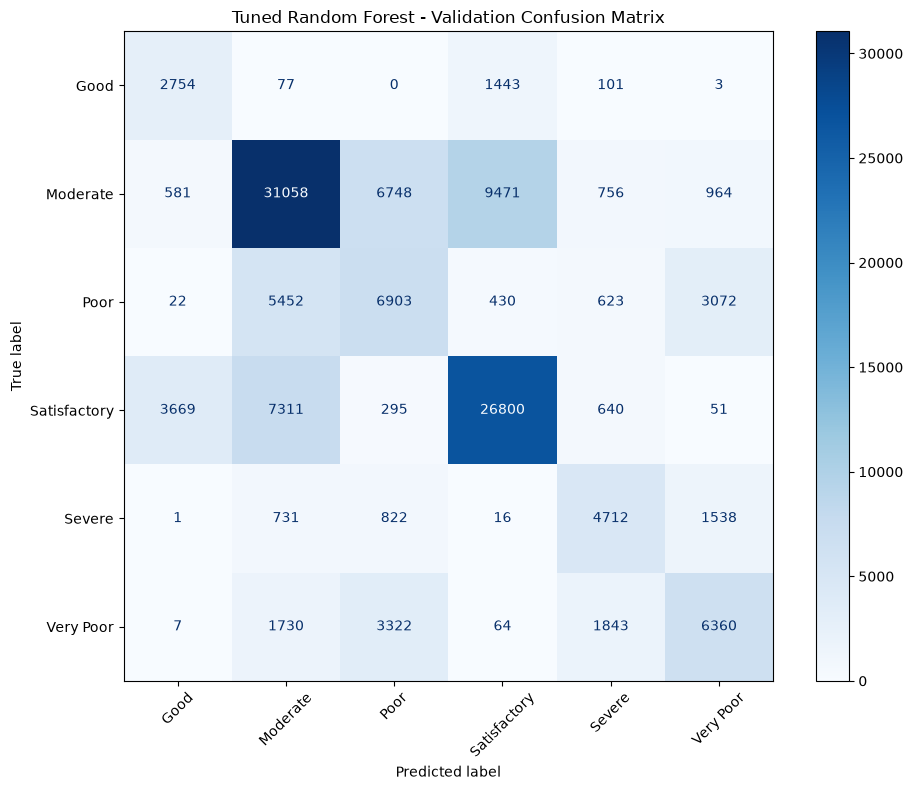

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_val,
    y_val_pred_split,
    labels=rf_split_controlled.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_split_controlled.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.xticks(rotation=45)
plt.title("Tuned Random Forest - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_val_pred_split))
print("Macro F1:", f1_score(y_val, y_val_pred_split, average="macro"))
print("Weighted F1:", f1_score(y_val, y_val_pred_split, average="weighted"))

labels = sorted(y_val.unique())

print("\nConfusion Matrix:")
print("Labels:", labels)
print(confusion_matrix(y_val, y_val_pred_split, labels=labels))

Accuracy: 0.6027997238628519
Macro F1: 0.54987228763045
Weighted F1: 0.6055982031954158

Confusion Matrix:
Labels: ['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor']
[[ 2754    77     0  1443   101     3]
 [  581 31058  6748  9471   756   964]
 [   22  5452  6903   430   623  3072]
 [ 3669  7311   295 26800   640    51]
 [    1   731   822    16  4712  1538]
 [    7  1730  3322    64  1843  6360]]
